In [1]:
import os
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

I0000 00:00:1787207851.710746    6659 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [5]:
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

IMAGE_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju0s2a9ekvms080138tjjpxr.jpg"
GT_POLYP_MASK_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju0s2a9ekvms080138tjjpxr.jpg"
MODEL_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/conference/claude/best_tf_dual_decoder_unet_v1.0.1.keras"

IMG_SIZE = (256, 256)

In [6]:
# --- rebuild architecture (needed to load this checkpoint, see last message) ---
def squeeze_and_excitation(x, ratio=16):
    f = x.shape[-1]
    s = tf.keras.layers.GlobalAveragePooling2D()(x)
    s = tf.keras.layers.Reshape((1, 1, f))(s)
    s = tf.keras.layers.Dense(f // ratio, activation="relu", use_bias=False)(s)
    s = tf.keras.layers.Dense(f, activation="sigmoid", use_bias=False)(s)
    return tf.keras.layers.Multiply()([x, s])

def _sp_shape(input_shape):
    return input_shape[:-1] + (1,)

def cbam_block(x, ratio=16):
    f = x.shape[-1]
    d1 = tf.keras.layers.Dense(f // ratio, activation="relu", use_bias=False)
    d2 = tf.keras.layers.Dense(f, use_bias=False)

    avg = tf.keras.layers.Reshape((1, 1, f))(tf.keras.layers.GlobalAveragePooling2D()(x))
    mx = tf.keras.layers.Reshape((1, 1, f))(tf.keras.layers.GlobalMaxPooling2D()(x))
    ch_att = tf.keras.layers.Activation("sigmoid")(
        tf.keras.layers.Add()([d2(d1(avg)), d2(d1(mx))])
    )
    x = tf.keras.layers.Multiply()([x, ch_att])

    avg_sp = tf.keras.layers.Lambda(lambda z: tf.reduce_mean(z, axis=-1, keepdims=True), output_shape=_sp_shape)(x)
    max_sp = tf.keras.layers.Lambda(lambda z: tf.reduce_max(z, axis=-1, keepdims=True), output_shape=_sp_shape)(x)
    concat = tf.keras.layers.Concatenate(axis=-1)([avg_sp, max_sp])
    sp_att = tf.keras.layers.Conv2D(1, 7, padding="same", activation="sigmoid", use_bias=False)(concat)
    return tf.keras.layers.Multiply()([x, sp_att])

def se_encoder_block(x, filters):
    x = tf.keras.layers.Conv2D(filters, 3, padding="same")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    x = tf.keras.layers.Conv2D(filters, 3, padding="same")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    x = squeeze_and_excitation(x)
    return x, tf.keras.layers.MaxPooling2D((2, 2))(x)

def cbam_decoder_block(x, skip, filters):
    x = tf.keras.layers.Conv2DTranspose(filters, 2, strides=2, padding="same")(x)
    x = tf.keras.layers.Concatenate()([x, skip])
    x = tf.keras.layers.Conv2D(filters, 3, padding="same")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    x = tf.keras.layers.Conv2D(filters, 3, padding="same")(x)
    x = tf.keras.layers.BatchNormalization()(x)
    x = tf.keras.layers.Activation("relu")(x)
    return cbam_block(x)

def build_dual_decoder_unet(input_shape=(256, 256, 3)):
    inputs = tf.keras.layers.Input(input_shape)
    s1, p1 = se_encoder_block(inputs, 64)
    s2, p2 = se_encoder_block(p1, 128)
    s3, p3 = se_encoder_block(p2, 256)
    s4, p4 = se_encoder_block(p3, 512)

    b1 = tf.keras.layers.Conv2D(1024, 3, padding="same")(p4)
    b1 = tf.keras.layers.BatchNormalization()(b1)
    b1 = tf.keras.layers.Activation("relu")(b1)
    b1 = tf.keras.layers.Conv2D(1024, 3, padding="same")(b1)
    b1 = tf.keras.layers.BatchNormalization()(b1)
    b1 = tf.keras.layers.Activation("relu")(b1)
    b1 = squeeze_and_excitation(b1)

    h = cbam_decoder_block(b1, s4, 512)
    h = cbam_decoder_block(h, s3, 256)
    h = cbam_decoder_block(h, s2, 128)
    h = cbam_decoder_block(h, s1, 64)
    healthy_output = tf.keras.layers.Conv2D(1, 1, padding="same", activation="sigmoid", name="healthy_output")(h)

    d = cbam_decoder_block(b1, s4, 512)
    d = cbam_decoder_block(d, s3, 256)
    d = cbam_decoder_block(d, s2, 128)
    d = cbam_decoder_block(d, s1, 64)
    polyp_output = tf.keras.layers.Conv2D(1, 1, padding="same", activation="sigmoid", name="polyp_output")(d)

    return tf.keras.models.Model(inputs, {"healthy_output": healthy_output, "polyp_output": polyp_output})

model = build_dual_decoder_unet()
model.load_weights(MODEL_PATH)

In [7]:
# --- preprocess (same as training: resize, CLAHE, sharpen, gaussian) ---
def apply_clahe(img):
    lab = cv2.cvtColor(img, cv2.COLOR_RGB2LAB)
    l, a, b = cv2.split(lab)
    l = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(l)
    return cv2.cvtColor(cv2.merge((l, a, b)), cv2.COLOR_LAB2RGB)

def apply_sharpen(img):
    k = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]])
    return cv2.filter2D(img, -1, k)

img = cv2.cvtColor(cv2.imread(IMAGE_PATH), cv2.COLOR_BGR2RGB)
img = cv2.resize(img, IMG_SIZE, interpolation=cv2.INTER_AREA)

proc = cv2.GaussianBlur(apply_sharpen(apply_clahe(img)), (3, 3), 0)
model_input = np.expand_dims(proc.astype(np.float32) / 255.0, axis=0)

gt_mask = cv2.imread(GT_POLYP_MASK_PATH, cv2.IMREAD_GRAYSCALE)
gt_mask = cv2.resize(gt_mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST)

preds = model.predict(model_input, verbose=0)
healthy_pred = preds["healthy_output"][0, ..., 0]
polyp_pred = preds["polyp_output"][0, ..., 0]

I0000 00:00:1787210017.520017    7904 service.cc:153] XLA service 0x70e070051e70 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1787210017.520322    7904 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 4060 Laptop GPU, Compute Capability 8.9 (Driver: 12.7.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1787210018.148439    7904 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1787210022.174729    7904 cuda_dnn.cc:461] Loaded cuDNN version 92101
W0000 00:00:1787210029.268530   11589 hlo_rematerialization.cc:3204] Can't reduce memory use below 6.06GiB (6508124084 bytes) by rematerialization; only reduced to 16.26GiB (17458921504 bytes), down from 16.26GiB (17458921504 bytes) originally
W0000 00:00:1787210040.288493    7904 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 16.25GiB (rounded to 17450533376)req

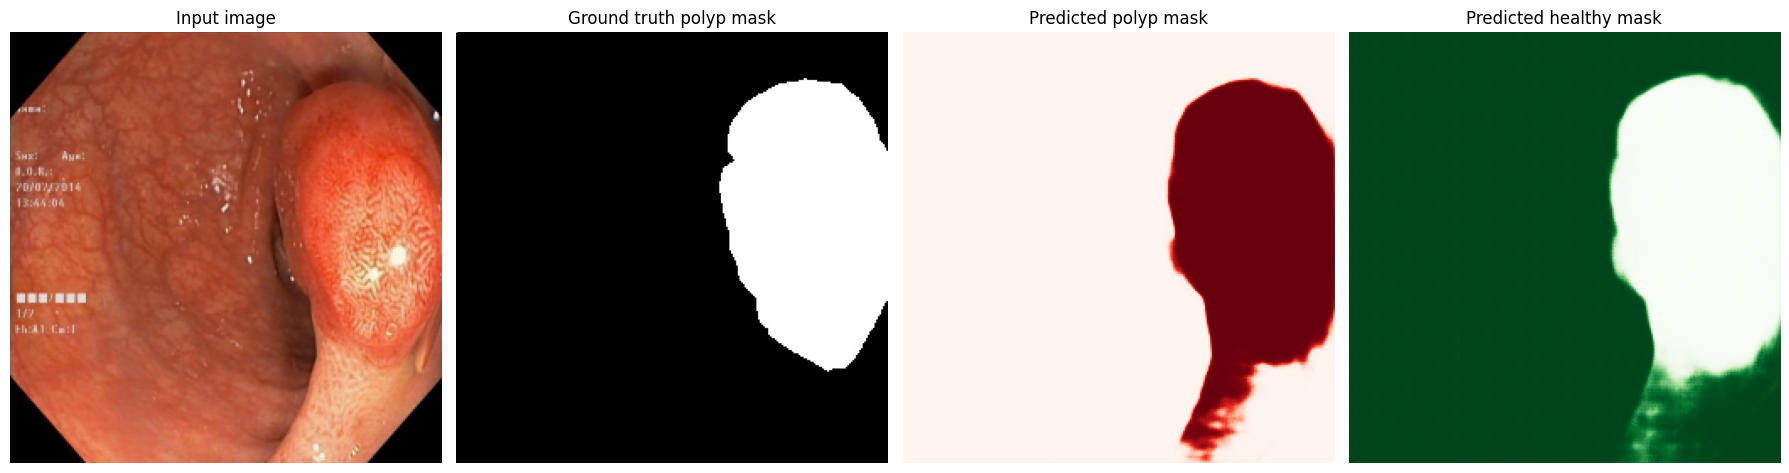

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(img)
axes[0].set_title("Input image")
axes[0].axis("off")

axes[1].imshow(gt_mask, cmap="gray")
axes[1].set_title("Ground truth polyp mask")
axes[1].axis("off")

axes[2].imshow(polyp_pred, cmap="Reds")
axes[2].set_title("Predicted polyp mask")
axes[2].axis("off")

axes[3].imshow(healthy_pred, cmap="Greens")
axes[3].set_title("Predicted healthy mask")
axes[3].axis("off")

plt.tight_layout()
plt.show()

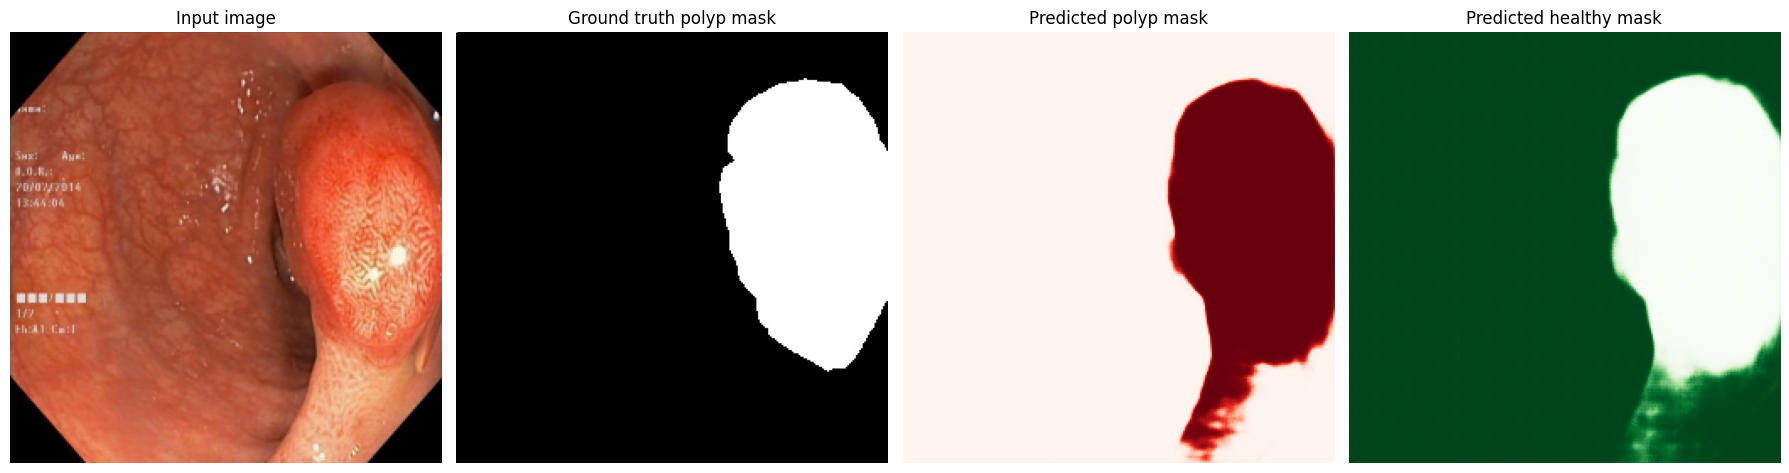

In [10]:
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

IMAGE_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju2r6mt2om21099352pny5gw.jpg"
GT_POLYP_MASK_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju2r6mt2om21099352pny5gw.jpg"
MODEL_PATH = "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/models/conference/claude/best_tf_dual_decoder_unet_v1.0.1.keras"

IMG_SIZE = (256, 256)
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

axes[0].imshow(img)
axes[0].set_title("Input image")
axes[0].axis("off")

axes[1].imshow(gt_mask, cmap="gray")
axes[1].set_title("Ground truth polyp mask")
axes[1].axis("off")

axes[2].imshow(polyp_pred, cmap="Reds")
axes[2].set_title("Predicted polyp mask")
axes[2].axis("off")

axes[3].imshow(healthy_pred, cmap="Greens")
axes[3].set_title("Predicted healthy mask")
axes[3].axis("off")

plt.tight_layout()
plt.show()

In [12]:
def show_segmentation(image_path, gt_mask_path=None, img_size=IMG_SIZE):
    """Runs the model on one image and displays input / GT mask (optional) /
    predicted polyp mask / predicted healthy mask, side by side."""
    img = cv2.cvtColor(cv2.imread(image_path), cv2.COLOR_BGR2RGB)
    img = cv2.resize(img, img_size, interpolation=cv2.INTER_AREA)

    proc = cv2.GaussianBlur(apply_sharpen(apply_clahe(img)), (3, 3), 0)
    model_input = np.expand_dims(proc.astype(np.float32) / 255.0, axis=0)

    preds = model.predict(model_input, verbose=0)
    healthy_pred = preds["healthy_output"][0, ..., 0]
    polyp_pred = preds["polyp_output"][0, ..., 0]

    gt_mask = None
    if gt_mask_path:
        gt_mask = cv2.imread(gt_mask_path, cv2.IMREAD_GRAYSCALE)
        gt_mask = cv2.resize(gt_mask, img_size, interpolation=cv2.INTER_NEAREST)

    n = 4 if gt_mask is not None else 3
    fig, axes = plt.subplots(1, n, figsize=(4.5 * n, 5))

    axes[0].imshow(img)
    axes[0].set_title("Input image")
    axes[0].axis("off")

    i = 1
    if gt_mask is not None:
        axes[i].imshow(gt_mask, cmap="gray")
        axes[i].set_title("Ground truth polyp mask")
        axes[i].axis("off")
        i += 1

    axes[i].imshow(polyp_pred, cmap="Reds")
    axes[i].set_title("Predicted polyp mask")
    axes[i].axis("off")
    i += 1

    axes[i].imshow(healthy_pred, cmap="Greens")
    axes[i].set_title("Predicted healthy mask")
    axes[i].axis("off")

    plt.tight_layout()
    plt.show()

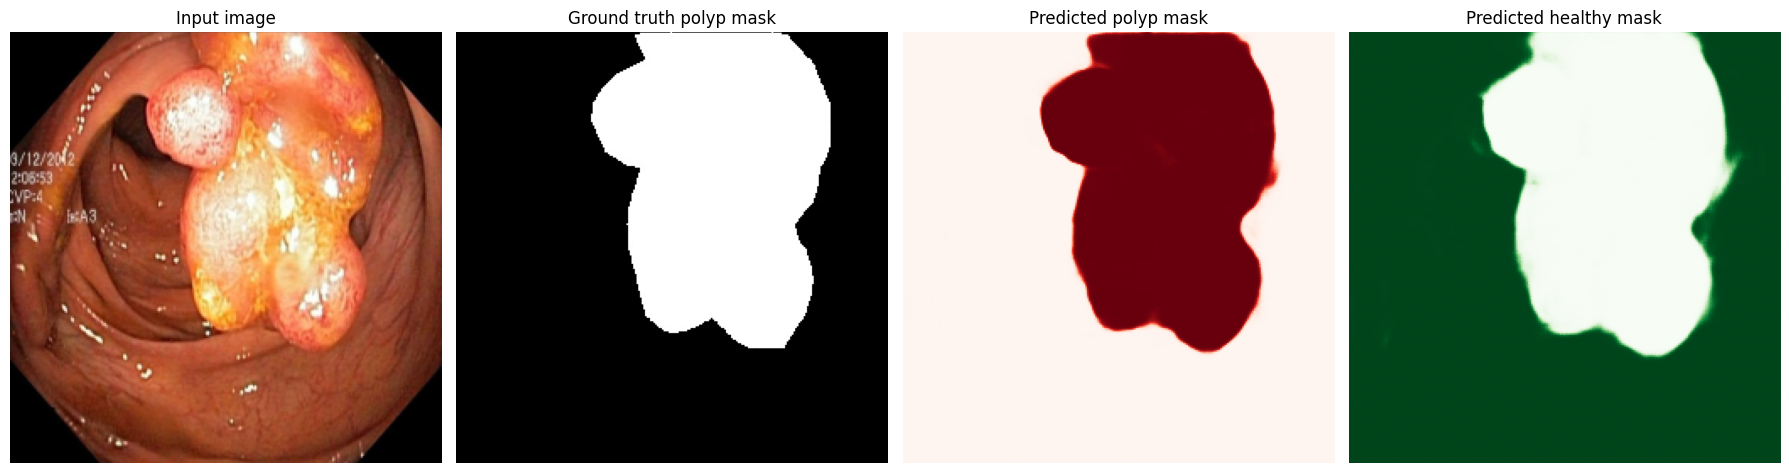

In [13]:
show_segmentation(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju2r6mt2om21099352pny5gw.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju2r6mt2om21099352pny5gw.jpg",
)

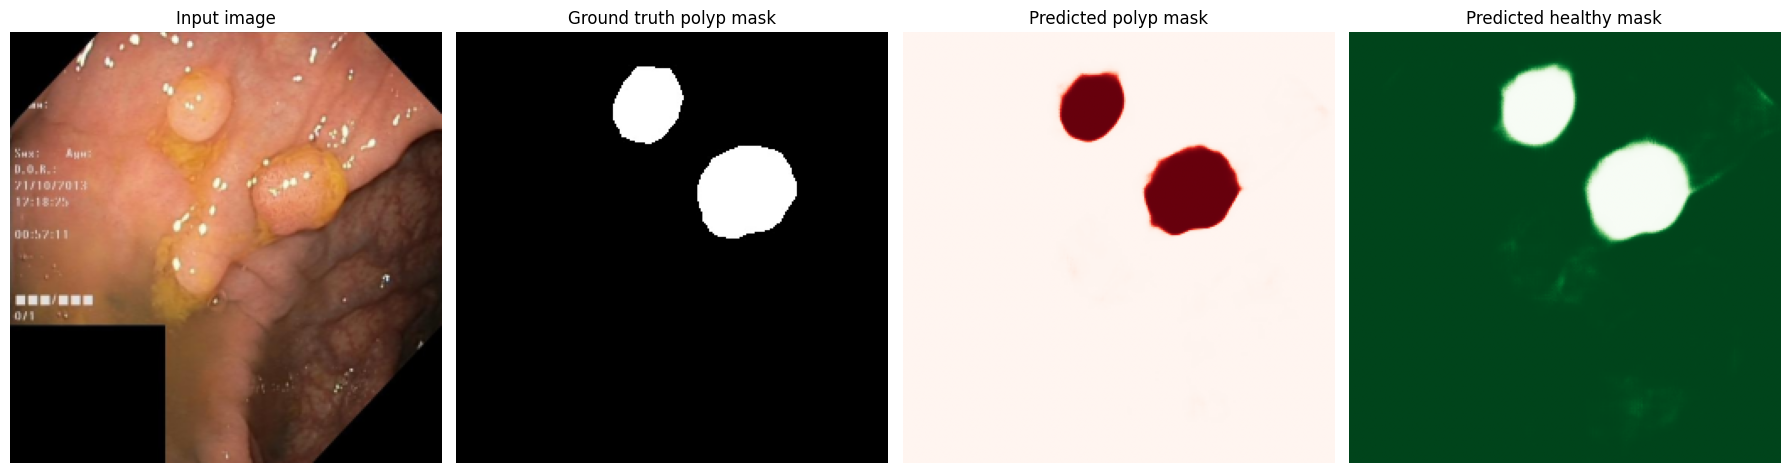

In [14]:
show_segmentation(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju6v1m1xv07w09870ah3njy1.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju6v1m1xv07w09870ah3njy1.jpg",
)

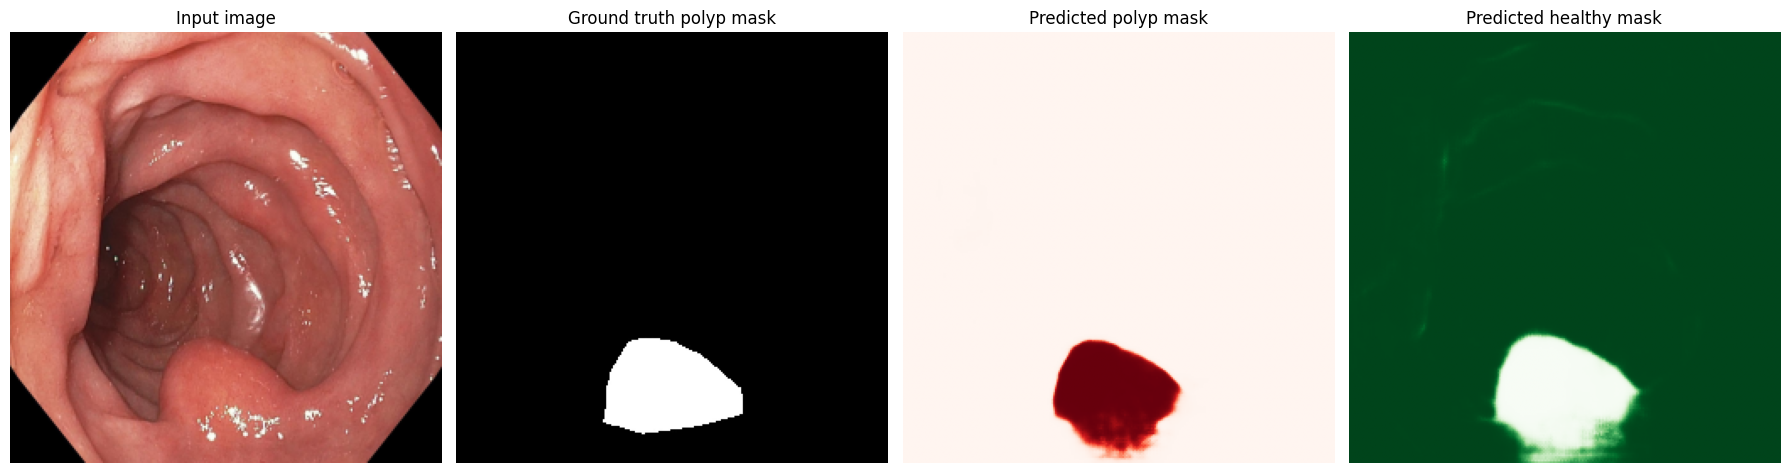

In [16]:
show_segmentation(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju40wto5kxwi0755it190f2k.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju40wto5kxwi0755it190f2k.jpg",
)

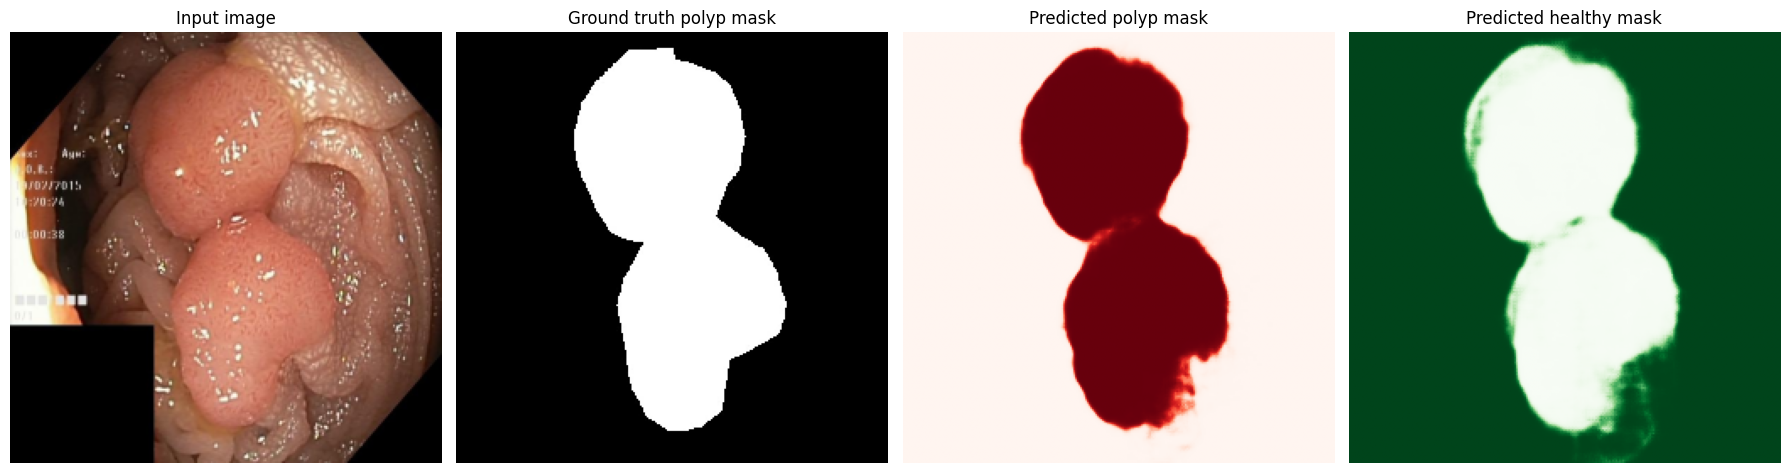

In [17]:
show_segmentation(
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/images/cju34aozyyy830993bn16u32n.jpg",
    "/mnt/c/development/Thesis/PolypSegmentationBasedClassification/DataSets/Kvasir-SEG/masks/cju34aozyyy830993bn16u32n.jpg",
)